*updated 22 Nov 2026, Julian Mak (whatever with copyright, do what you want with this)

### As part of material for OCES 3301 "Data Analysis in Ocean Sciences" delivered at HKUST

For the latest version of the material, go to the public facing [GitHub](https://github.com/julianmak/academic-notes/tree/master/OCES3301_data_analysis_ocean) page.

---------------------------

# bonus: GIS of sorts

GIS stands for ***Geographic Information System***, and involve manipulating data of relevance to geography (although the underlying ideas we will see are more generalisable). This can show up in oceanography I suppose, but not that often as far as I can tell, at least for the things I want to demonstrate here relating to **vector** data. The examples below use city data in HK that I can get hold of.

GIS is in my opinion both easier and harder than it should be. Sometimes it is regarded as "hard" because there is a technical threshold for understanding/learning what operations that standard proprietary software are doing, and the data that sometimes come with it is incomplete and somewhat annoying to deal with (there is an example below). The below hopefully convinces you at the very basic level it is actually reasonably "easy" (even if it can be quite tedious): it really is just manipulating **vector** and **raster** data, which may not be so obvious if you use proprietary software (so there is benefit in this sense with doing things the old fashioned way).

**Raster** data is just data that are represented as pixels on some grid, which we basically dealt with already in `09/10_fun_with_maps` (so yes this course actually does have GIS related things already, I just don't particularly feel like selling it that way). **Vector** data on the other hand concerns points, lines/curves, surfaces/polygons and related objects. As an example, I would usually store SST data as raster data, while coastlines I may want to store as vector data instead (otherwise I would have very jagged coastlines that have some area/volume associated with it). I may want to compute lines of constant SST from the raster data as a boundary curve, and then store as vector data, or vice-versa to reconstruct the raster data by inteprolation. If the lines of constant SST is closed, I may want to talk about the area enclosed by that curve (e.g., say I want an area of an area I identified as a marine heatwave), find the centres of the area enclosed, find the distance between two areas (minimum, maximum, distance between "centers", etc.), how regions are connected, and so forth. It really depends on the context.

Since we have already dealt with raster data the notebook here focuses on vector data. The two packages we will be using are `shapely` for demonstrating things with vector data, and `geopandas` for reading the relevant data (the ones below we deal with are GeoJSON data `json` or `geojson`, and these are really just text files), and you use it basically like `pandas`. Will also leverage a bit of `cartopy` and extend a bit of what was done in `10_fun_with_maps`.

> NOTE: `geopandas` and `shapely` should be on Colab already.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import urllib

import geopandas as gpd
import shapely as shp
from matplotlib.patches import PathPatch
from matplotlib.path import Path
from shapely.affinity import rotate, scale, translate
from shapely.geometry import LineString, Point, Polygon
import cartopy
import cartopy.crs as ccrs

print(f"gpd version: {gpd.__version__}")
print(f"shp version: {shp.__version__}")

gpd version: 1.2.0
shp version: 2.1.1


---
# a) `Shapely`

The basic components we will be dealing with are the following:

* `Point`, describe by its co-ordinates.
* `LineString`, a curve with straight line segments that could exist by itself (when specifying the co-ordinates), or actually join up a collection of `Points`.
* `Polygon`, a set of `LineString` that closes on itself.

We could also draw circles, ellipses and more sophisticated geometric/topological objects (e.g., torus or doughnuts). Below shows a few of these; I didn't bother putting them on a canvas, and in this sense the co-ordinates are somewhat irrelevant when I call the rendering with `display()`.

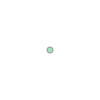

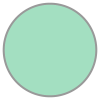

In [2]:
# build a point and demonstrate buffer
pupil_l = Point(-0.50, 2.05)
pupil_r = Point(0.50, 2.05).buffer(0.06)

display(pupil_l, pupil_r.buffer(0.06))

pupil_l = Point(-0.50, 2.05).buffer(0.06)

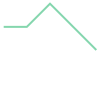

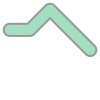

In [3]:
# demonstrate drawing a line

strand = LineString([[0.0, 0.0], [1.0, 0.0], [2.0, 1.0], [4.0, -1.0]])
display(strand, strand.buffer(0.3))

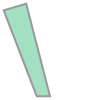

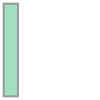

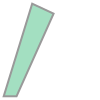

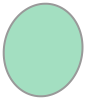

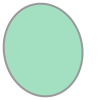

In [4]:
# other geometric objects
hair_1 = Polygon([(-0.1, 3.0), (-0.35, 3.65), (-0.18, 3.70), (0.0, 3.0)])
hair_2 = Polygon([(-0.04, 3.02), (-0.04, 3.80), (0.08, 3.80), (0.08, 3.02)])
hair_3 = Polygon([(0.05, 3.0), (0.25, 3.65), (0.40, 3.58), (0.14, 3.0)])

def create_ellipse(cx, cy, rx, ry, angle=0):
    circle = Point(0, 0).buffer(1.0, resolution=64)
    ellipse = scale(circle, rx, ry)
    if angle != 0:
        ellipse = rotate(ellipse, angle, origin=(0, 0))
    return translate(ellipse, cx, cy)

eye_l = create_ellipse(-0.55, 2.05, 0.32, 0.38, angle=-10)
eye_r = create_ellipse(0.55, 2.05, 0.32, 0.38, angle=10)

display(hair_1, hair_2, hair_3, eye_l, eye_r)

There are various operations I can do, such as:

* `union`, where I combine things if they are in one set `or` the other.
* `intersection`, where I include things that are in one set `and` the other.
* `difference`, if one set overlaps the other, I can take the latter set of like in `subtraction`.

There are many others, and you can have a look at the [shapely manual](https://shapely.readthedocs.io/en/stable/manual.html#operations) for those. Below is an example of doing `union` (`unary` here broadly just means I combine everything in one go).

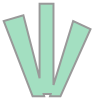

In [5]:
# operations on things
hair = shp.ops.unary_union([hair_1, hair_2, hair_3])
display(hair)

I may want to have some quantitive measures associated with the resulting object(s), such as the area (if it is a proper 2d object), length (if it is a 1d object, for example if I take the `boundary` of the object above), the `centroid` of the object as a representative point, and so forth. Below shows an example of computing the `centroid`, `area`, `boundary` and the `length` of boundary.

> NOTE: I didn't specify units here so all quantities are unitless. Later example do have appropriate units.

In [6]:
# computing areas and centroids
print(f"center point at = {hair.centroid}")
print(f"polygon has area = {hair.area:.6f}")
print(f"polygon boundary length = {hair.boundary.length:.6f}")

center point at = POINT (0.0142637193057546 3.3793773324743563)
polygon has area = 0.268663
polygon boundary length = 4.574795


Below I combine a whole load of things and actually put it on a canvas and appropriately colour things to generate an image purely from elementary shapes and basic operations.

> NOTE: This one I got automagically from Google AI, apologies to whoever actually made this code...

In [7]:
# misc bits
head = create_ellipse(0, 1.8, 1.35, 1.25)
torso = create_ellipse(0, -0.3, 1.75, 1.85)
tail = Polygon([(-1.3, -1.2), (-2.3, -0.7), (-1.6, -1.7)])
left_arm = create_ellipse(-1.45, 1.4, 0.45, 0.95, angle=32)
right_arm = create_ellipse(1.45, 1.4, 0.45, 0.95, angle=-32)
body_union = shp.ops.unary_union([head, torso, tail, left_arm, right_arm])

beak_upper = create_ellipse(0, 1.25, 0.95, 0.45)
beak_lower = create_ellipse(0, 0.95, 1.15, 0.55)
beak = shp.ops.unary_union([beak_upper, beak_lower])

nostril_l = create_ellipse(-0.22, 1.42, 0.04, 0.08, angle=15)
nostril_r = create_ellipse(0.22, 1.42, 0.04, 0.08, angle=-15)

foot_l = Polygon([(-1.2, -2.0), (-0.4, -2.0), (-0.2, -2.5), (-0.8, -2.35), (-1.4, -2.5)]).buffer(0.12)
foot_r = Polygon([(0.4, -2.0), (1.2, -2.0), (1.4, -2.5), (0.8, -2.35), (0.2, -2.5)]).buffer(0.12)

def plot_shapely_poly(ax, geom, facecolor, edgecolor="black", linewidth=2, zorder=1):
    if geom.is_empty:
        return
    geoms = [geom] if geom.geom_type == "Polygon" else list(geom.geoms)
    for poly in geoms:
      ext = np.array(poly.exterior.coords)
      path_data = [(Path.MOVETO, ext[0])] + [(Path.LINETO, pt) for pt in ext[1:]]
      codes, verts = zip(*path_data)
      patch = PathPatch(
          Path(verts, codes),
          facecolor=facecolor,
          edgecolor=edgecolor,
          linewidth=linewidth,
          zorder=zorder,
      )
    ax.add_patch(patch)

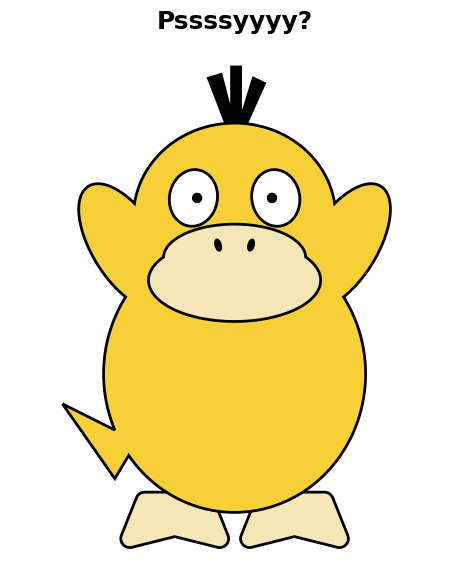

In [8]:
# plot the whole thing out
fig, ax = plt.subplots(figsize=(6, 7))
ax.set_aspect("equal")
ax.set_xlim(-3.0, 3.0)
ax.set_ylim(-3.0, 4.2)
ax.axis("off")

# Colors
YELLOW = "#F7D038"
CREAM = "#F5E6B8"

plot_shapely_poly(ax, hair, facecolor="black", zorder=1)
plot_shapely_poly(ax, foot_l, facecolor=CREAM, zorder=2)
plot_shapely_poly(ax, foot_r, facecolor=CREAM, zorder=2)
plot_shapely_poly(ax, body_union, facecolor=YELLOW, zorder=3)
plot_shapely_poly(ax, eye_l, facecolor="white", zorder=4)
plot_shapely_poly(ax, eye_r, facecolor="white", zorder=4)
plot_shapely_poly(ax, pupil_l, facecolor="black", linewidth=1, zorder=5)
plot_shapely_poly(ax, pupil_r, facecolor="black", linewidth=1, zorder=5)
plot_shapely_poly(ax, beak, facecolor=CREAM, zorder=6)
plot_shapely_poly(ax, nostril_l, facecolor="black", linewidth=1, zorder=7)
plot_shapely_poly(ax, nostril_r, facecolor="black", linewidth=1, zorder=7)

ax.set_title("Pssssyyyy?", fontsize=18, fontweight="bold");

---

# b) Using `geopandas`

Below we load some data I got from various places relating to HK city. First one we will do is one that is reasonably complete for the 18 adminstrative districts of HK that I got from the [government data website](https://data.gov.hk/en-data/dataset/hk-had-json1-hong-kong-administrative-boundaries/resource/855f034a-c330-435c-a911-1d63538a6d55) directly. The file I made avaiable on my GitHub just so I can do remote loads.

In [9]:
option = "remote"

if option == "local":
    print("loading data locally (assumes file has already been downloaded)")
    f = open("hksar_18_district_boundary.json", "r")
elif option == "remote":
    print("loading data remotely")
    path = "https://raw.githubusercontent.com/julianmak/OCES3301_data_analysis/refs/heads/main/hksar_18_district_boundary.json"
    f = urllib.request.urlopen(path)
else:
    raise ValueError("INVALID OPTION: use 'remote' or 'local'")

district_polygon = gpd.read_file(path)
display(district_polygon)

loading data remotely


,地區號碼,District,地區,Administrative_District_Boundary_of_Hong_Kong,geometry
0,M,Yuen Long District,元朗區,Administrative District Boundary of Hong Kong,"POLYGON ((114.06596 22.39182, 114.06605 22.391..."
1,D,Southern District,南區,Administrative District Boundary of Hong Kong,"POLYGON ((114.16338 22.25882, 114.16305 22.258..."
2,B,Wan Chai District,灣仔區,Administrative District Boundary of Hong Kong,"POLYGON ((114.19772 22.2579, 114.19778 22.2580..."
3,A,Central and Western District,中西區,Administrative District Boundary of Hong Kong,"POLYGON ((114.14951 22.29748, 114.10986 22.297..."
4,C,Eastern District,東區,Administrative District Boundary of Hong Kong,"POLYGON ((114.21939 22.29568, 114.21087 22.300..."
5,T,Islands District,離島區,Administrative District Boundary of Hong Kong,"POLYGON ((113.93955 22.14848, 113.9707 22.1485..."
6,E,Yau Tsim Mong District,油尖旺區,Administrative District Boundary of Hong Kong,"POLYGON ((114.17447 22.32665, 114.17417 22.326..."
7,J,Kwun Tong District,觀塘區,Administrative District Boundary of Hong Kong,"POLYGON ((114.22403 22.33452, 114.22398 22.334..."
8,F,Sham Shui Po District,深水埗區,Administrative District Boundary of Hong Kong,"POLYGON ((114.17273 22.34647, 114.17258 22.346..."
9,G,Kowloon City District,九龍城區,Administrative District Boundary of Hong Kong,"POLYGON ((114.17945 22.34902, 114.179 22.34909..."


As with `pandas` the resulting object is a (Geo)DataFrame, with the addition of a `geometry` attribute. You can do the usual query and statistics things as in `pandas`, but there are more things one can do with the extra `geometry` attribute, some of which will be demonstrated as we progress.

This data is reasonably simple, and you can see that under the `geometry` entry of the table it's a `Polygon` object with presumably the co-ordinates of the vertices for the polygon. We can brute force plot out what this looks like by calling the intrinsic `.plot()` associated with this GeoDataFrame.

> NOTE: I am going to rely on the intrinsic plotting but I will predefine an axes that the plotting we happen on, so there are a few `ax=ax` commands floating around.

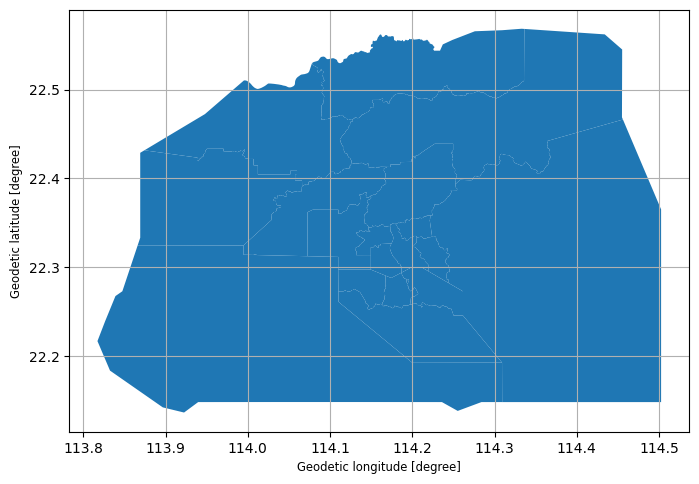

In [10]:
fig = plt.figure(figsize=(8, 6))
ax = plt.axes()
district_polygon.plot(ax=ax)
ax.grid()

Does not obviously look like HK maybe, but you have to remember this is the *adminstrative* districts, which does not necessary restrict itself to being on land.

To have a useful reference it would be easier to plot out the outline of the HK land and coastline, which I do with `cartopy` below. I also make it a bit easier to read by only plotting out the boundaries of the polygon instead of filling it up.

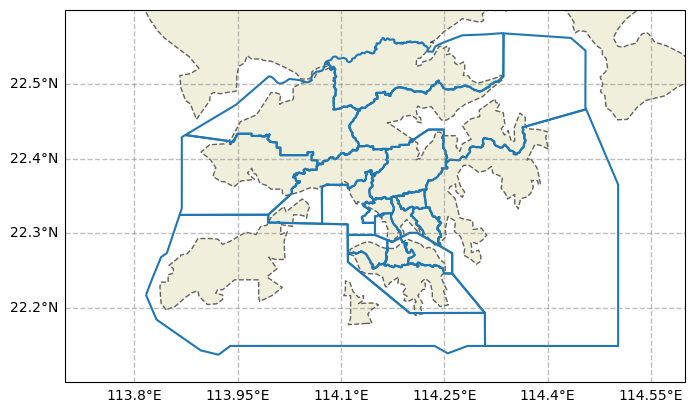

In [11]:
fig = plt.figure(figsize=(8, 6))
ax = plt.axes(projection = ccrs.PlateCarree())
district_polygon.boundary.plot(ax=ax, color="C0")
ax.set_extent([113.7, 114.6, 22.1, 22.6],ccrs.PlateCarree())
gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                  linewidth=1, color='gray', alpha=0.5, linestyle='--')
gl.top_labels = False
gl.right_labels = False

ax.add_feature(cartopy.feature.LAND)
ax.coastlines(alpha=0.6, linestyle="--")

A bit easier to find the reference points now maybe.

One thing I may want to do is to compute the areas of the administrative regions. The thing you do have to be careful here is that the co-ordinates given above are in `(lon, lat)`, but there is some curvature of the Earth, so a brute force compute of the area may be problematic. The thing we probably want to do is to project things accordingly, which is effectively choosing a localised reference system. This is all built into `geopandas`, and we can query the existing projection by calling the GeoDataFrame attribute `.crs`, and converting it accordingly with `.to_crs(WHATEVER)`. For HK apparently we want `.to_crs(epsg=2326)`; below the returned area is in units of $mathrm{m}^2$, and I convert the area into $\mathrm{km}^2$ with a conversion factor.

> NOTE: The only thing I said in `10_fun_with_maps` is that there is no global isometry between the sphere and the 2d plane. Here if we are dealing with local slices we are probably ok, or at least able to choose a projection that is more accurate with our local slice.

In [12]:
display(district_polygon.crs)

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [13]:
district_polygon["area (km2)"] = district_polygon.to_crs(epsg=2326).area / (1e6)
district_polygon

,地區號碼,District,地區,Administrative_District_Boundary_of_Hong_Kong,geometry,area (km2)
0,M,Yuen Long District,元朗區,Administrative District Boundary of Hong Kong,"POLYGON ((114.06596 22.39182, 114.06605 22.391...",188.468497
1,D,Southern District,南區,Administrative District Boundary of Hong Kong,"POLYGON ((114.16338 22.25882, 114.16305 22.258...",93.991667
2,B,Wan Chai District,灣仔區,Administrative District Boundary of Hong Kong,"POLYGON ((114.19772 22.2579, 114.19778 22.2580...",12.342655
3,A,Central and Western District,中西區,Administrative District Boundary of Hong Kong,"POLYGON ((114.14951 22.29748, 114.10986 22.297...",19.755013
4,C,Eastern District,東區,Administrative District Boundary of Hong Kong,"POLYGON ((114.21939 22.29568, 114.21087 22.300...",26.093909
5,T,Islands District,離島區,Administrative District Boundary of Hong Kong,"POLYGON ((113.93955 22.14848, 113.9707 22.1485...",664.736621
6,E,Yau Tsim Mong District,油尖旺區,Administrative District Boundary of Hong Kong,"POLYGON ((114.17447 22.32665, 114.17417 22.326...",11.457239
7,J,Kwun Tong District,觀塘區,Administrative District Boundary of Hong Kong,"POLYGON ((114.22403 22.33452, 114.22398 22.334...",13.962807
8,F,Sham Shui Po District,深水埗區,Administrative District Boundary of Hong Kong,"POLYGON ((114.17273 22.34647, 114.17258 22.346...",10.798899
9,G,Kowloon City District,九龍城區,Administrative District Boundary of Hong Kong,"POLYGON ((114.17945 22.34902, 114.179 22.34909...",14.443172


I may want to mark the regions according to the label, and one reasonable choice of the location for labelling is the `centroid` of the polygon. Here I first convert to a local frame, then compute the centroid, and then send it back to `(lon, lat)`.

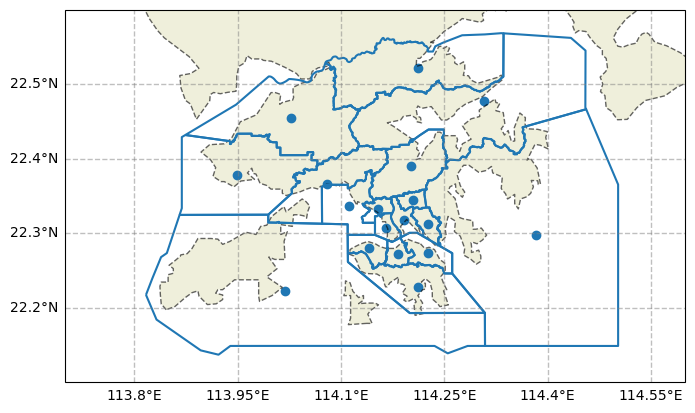

In [14]:
district_polygon["centroid"] = district_polygon.to_crs(epsg=2326).centroid.to_crs(district_polygon.crs)

fig = plt.figure(figsize=(8, 6))
ax = plt.axes(projection = ccrs.PlateCarree())
district_polygon.boundary.plot(ax=ax, color="C0")
district_polygon["centroid"].plot(ax=ax)
ax.set_extent([113.7, 114.6, 22.1, 22.6],ccrs.PlateCarree())
gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                  linewidth=1, color='gray', alpha=0.5, linestyle='--')
gl.top_labels = False
gl.right_labels = False

ax.add_feature(cartopy.feature.LAND)
ax.coastlines(alpha=0.6, linestyle="--")

Instead of labelling the points as dots, I additionally query what the labels are in the GeoDataFrame itself, and then mark the centroid location with the corresponding label. 

> NOTE: Matplotlib in this case appears to have complaints about rendering Chinese characters (or at least the font I chose is incompatible with Chinese characters). See if you can figure out how to get around that.

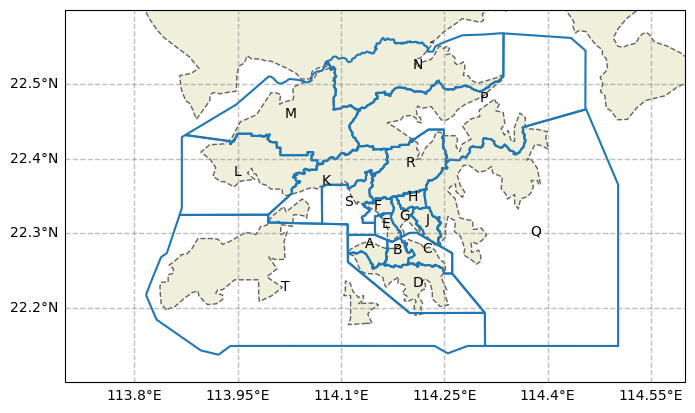

In [15]:
fig = plt.figure(figsize=(8, 6))
ax = plt.axes(projection = ccrs.PlateCarree())
district_polygon.boundary.plot(ax=ax, color="C0")
ax.set_extent([113.7, 114.6, 22.1, 22.6],ccrs.PlateCarree())
gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                  linewidth=1, color='gray', alpha=0.5, linestyle='--')
gl.top_labels = False
gl.right_labels = False

ax.add_feature(cartopy.feature.LAND)
ax.coastlines(alpha=0.6, linestyle="--")

for _, row in district_polygon.iterrows():
    ax.annotate(
        text=row["地區號碼"],
        xy=(row["centroid"].x, row["centroid"].y),
        ha='center',
    )

> <span style="color:red">**Q.**</span> Conceptually, have a think about how you might compute the *land* areas covered by the administrative regions, given the above polygons and say only what is given to you by `cartopy`? What operations (unions, intersect, differences) acting on what might you want to do?

Next thing I was going to do is to plot the MTR lines and stations accoringly. However I don't seem to be able to find easily usable data for that. The one I use below is from [here](https://data.humdata.org/dataset/hotosm_hkg_railways) and seems to include a lot of things I don't need, and out of the useful things I want only includes East Rail and Tsuen Ma line, which is not mega useful... Nevertheless it is good enough for illustrating a few things.

In [16]:
option = "remote"

if option == "local":
    print("loading data locally (assumes file has already been downloaded)")
    f = open("railways.geojson", "r")
elif option == "remote":
    print("loading data remotely")
    path = "https://raw.githubusercontent.com/julianmak/OCES3301_data_analysis/refs/heads/main/railways.geojson"
    f = urllib.request.urlopen(path)
else:
    raise ValueError("INVALID OPTION: use 'remote' or 'local'")

mtr_network = gpd.read_file(path)
display(mtr_network.head())

loading data remotely


,id,name,name_en,name_zh_Hant,railway,ele,operator_type,layer,addr_full,addr_city,...,adm1_pcode,adm1_name,adm2_pcode,adm2_name,adm3_pcode,adm3_name,adm4_pcode,adm4_name,name_latin,geometry
0,way/1488485643,None,None,None,rail,None,None,None,None,None,...,None,None,None,None,None,None,None,None,None,"LINESTRING (114.11026 22.56663, 114.1102 22.56..."
1,way/1488485639,None,None,None,rail,None,None,None,None,None,...,None,None,None,None,None,None,None,None,None,"LINESTRING (114.11049 22.56651, 114.11037 22.5..."
2,way/1488485619,None,None,None,rail,None,None,None,None,None,...,None,None,None,None,None,None,None,None,None,"LINESTRING (114.11049 22.56651, 114.11044 22.5..."
3,way/1488485621,None,None,None,rail,None,None,None,None,None,...,None,None,None,None,None,None,None,None,None,"LINESTRING (114.11036 22.56635, 114.11029 22.5..."
4,node/9310690695,笋岗,Sungang,None,station,None,None,None,None,None,...,None,None,None,None,None,None,None,None,Sungang,POINT (114.10586 22.56587)


Here you might already notice there are quite a few columns, and turns out most of them are basically spurious, so we probably want to remove those. You might also see there are some stations outside of the HK administrative area also. If we do a brute force plot we can see some of the "issues" with the data here.

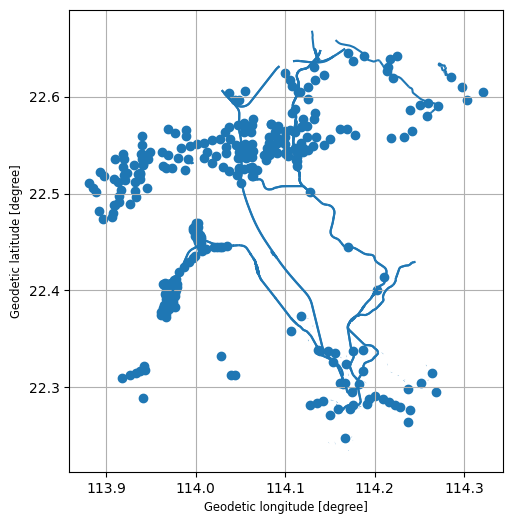

In [17]:
fig = plt.figure(figsize=(8, 6))
ax = plt.axes()
mtr_network.plot(ax=ax)
ax.grid()

As advertised there are fewer lines than we think we should have, and loads of stations that are actually in the Shenzhen area that we don't particularly need for our present purpose. Below I get rid of some of the columns that I manually inspected that add no useful information for my purposes, and also do a coarse filter by removing all the data entries that are sufficiently far north (here I took Lo Wu to be the reference point, and I query the latitude or the second co-ordinate by `.centroid.y`; `.x` would give longitude or the first co-ordinate).

> NOTE: In hindsight I didn't need to do any of this because I was just going to subselect the East Rail line, and below really is just demonstration of syntax for how one might tidy the GeoDataFrame a bit (e.g. if I want to outputting it and save other people the hassle).
>
> I am being lazy and not bothering to do the projections accordingly. In this instance I don't particularly care, so I am ignoring the warnings.

/tmp/ipykernel_128065/1378781394.py:7: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  mtr_clean = mtr_clean[mtr_clean.centroid.y <= 22.52818]  # example to only taken some stuff south of some latitude


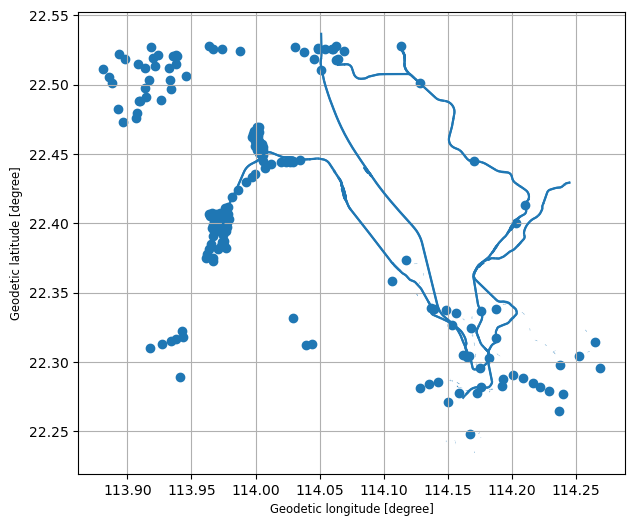

In [18]:
# drop some not useful columns
mtr_clean = mtr_network.drop(columns=["name_zh_Hant", "ele", "layer", "addr_full", "addr_city",
                                      "adm2_pcode", "adm2_name", 
                                      "adm3_pcode", "adm3_name", 
                                      "adm4_pcode", "adm4_name"])
# mtr_clean = mt_clean.to_crs(epsg=2326)  # convert to HK grid
mtr_clean = mtr_clean[mtr_clean.centroid.y <= 22.52818]  # example to only taken some stuff south of some latitude

fig = plt.figure(figsize=(8, 6))
ax = plt.axes()
mtr_clean.plot(ax=ax)
ax.grid()

Below I only pull out the lines and stations associated with the East Rail line. The line is labelled in the dataset, but the stations annoyingly are not, so I typed it out in full and did a query to pull it out accordingly. Going to make it tidy by putting it on a cartopy map and label the stations accordingly.

> NOTE: If you dig into the data you will find Kowloon Tong shows up twice for some reason, which is also why the Kowloon Tong text looks a bit funny on the map.
>
> You will find that `EastRail_line` is a `LineString`, while the uncleaned `EastRail_stations` are sometimes `Points` sometimes `Polygons` for reasons unknown to me. I just convert all the stations into `Points` by calling `.centroid` on them.

In [19]:
# only pick out EastRail and its stations

EastRail_line = mtr_clean[mtr_clean["name_latin"] == "MTR East Rail Line"]

stations_list = ["Admiralty", "Exhibition Centre", "Hung Hom",
                 "Mong Kok East", "Kowloon Tong", "Tai Wai", "Sha Tin",
                 "Fo Tan", "University", "Tai Po Market", "Tai Wo",
                 "Fanling", "Sheung Shui", "Lo Wu", "Lok Ma Chau"]

EastRail_stations = mtr_clean[mtr_clean["name_latin"].isin(stations_list)].copy()
EastRail_stations["geometry"] = EastRail_stations.centroid  # force these into points

/tmp/ipykernel_128065/1378392245.py:11: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  EastRail_stations["geometry"] = EastRail_stations.centroid  # force these into points


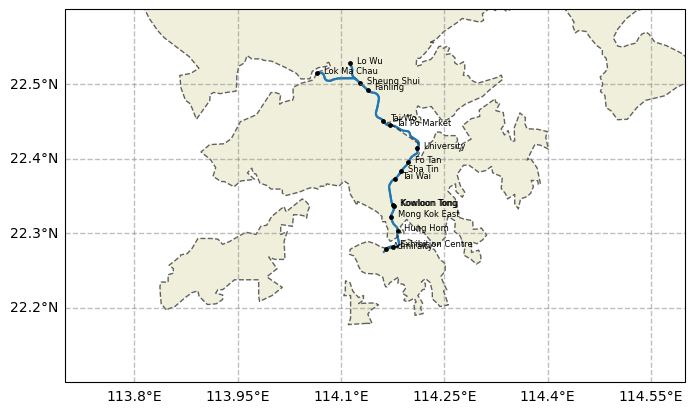

In [20]:
# cartopy it also
fig = plt.figure(figsize=(8, 6))
ax = plt.axes(projection = ccrs.PlateCarree())
EastRail_line.plot(ax=ax, zorder=1)
EastRail_stations.plot(ax=ax, color="k", markersize=6)
ax.set_extent([113.7, 114.6, 22.1, 22.6],ccrs.PlateCarree())
gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                  linewidth=1, color='gray', alpha=0.5, linestyle='--')
gl.top_labels = False
gl.right_labels = False

ax.add_feature(cartopy.feature.LAND)
ax.coastlines(alpha=0.6, linestyle="--")

# add in the station names with an offset
for _, row in EastRail_stations.iterrows():
    ax.annotate(
        text=row["name_en"],
        xy=(row["geometry"].x + 0.01, row["geometry"].y),  # cheating here
        ha='left',
        fontsize=6,
    )

> <span style="color:red">**Q.**</span> Try and put on the Tuen Ma line and the associated stations on if you like.
>
> <span style="color:red">**Q.**</span> If you are feeling really adventurous, you can try and create the other MTR lines by approximating linear lines between the stations maybe. See how I do that with the examples in the next section.

Same game but now with the bus network. This data is better documented and cleaner in my opinion, but has the disadvantage that it is just bus stops, and there are no `LineString`s to represent the bus lines. For this I am going to create them manually by doing piecewise linear interpolation essentially (just going to join up the pairs of points with an appropriate pairwise ordering).

> NOTE: This data is a bit big so I didn't put it on my GitHub, and instead calling from the source directly (so may be subject to change as data gets updated every two weeks).

In [21]:
option = "remote"

if option == "local":
    print("loading data locally (assumes file has already been downloaded)")
    f = open("railways.geojson", "r")
elif option == "remote":
    print("loading data remotely")
    path = "https://static.data.gov.hk/td/routes-fares-geojson/JSON_BUS.json"
    f = urllib.request.urlopen(path)
else:
    raise ValueError("INVALID OPTION: use 'remote' or 'local'")

bus_network = gpd.read_file(path)
bus_network

loading data remotely


,routeId,companyCode,district,routeNameC,routeNameS,routeNameE,routeType,serviceMode,specialType,journeyTime,...,fullFare,lastUpdateDate,routeSeq,stopSeq,stopId,stopPickDrop,stopNameC,stopNameS,stopNameE,geometry
0,1001,KMB,,1,1,1,1,R,0,46,...,6.7,2026-05-22,1,1,4001,2,竹園邨總站,竹园邨总站,CHUK YUEN ESTATE BUS TERMINUS,POINT (114.19245 22.34535)
1,1001,KMB,,1,1,1,1,R,0,46,...,6.7,2026-05-22,1,2,4002,3,天虹小學,天虹小学,RAINBOW PRIMARY SCHOOL,POINT (114.19001 22.34506)
2,1001,KMB,,1,1,1,1,R,0,46,...,6.7,2026-05-22,1,3,4003,3,馬仔坑遊樂場,马仔坑游乐场,MA CHAI HANG RECREATION GROUND,POINT (114.18778 22.34422)
3,1001,KMB,,1,1,1,1,R,0,46,...,6.7,2026-05-22,1,4,4004,3,摩士公園,摩士公园,MORSE PARK,POINT (114.18939 22.33972)
4,1001,KMB,,1,1,1,1,R,0,46,...,6.7,2026-05-22,1,5,4005,3,摩士公園體育館,摩士公园体育馆,MORSE PARK SPORTS CENTRE,POINT (114.1899 22.3378)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
56156,1000742,KMB,,67M,67M,67M,1,T,1,29,...,5.1,2026-11-06,1,10,9827,3,景峰花園,景峰花园,PRIME VIEW GARDEN,POINT (113.97943 22.4032)
56157,1000742,KMB,,67M,67M,67M,1,T,1,29,...,5.1,2026-11-06,1,11,9818,3,新圍仔,新围仔,SAN WAI TSAI,POINT (113.97732 22.39779)
56158,1000742,KMB,,67M,67M,67M,1,T,1,29,...,5.1,2026-11-06,1,12,9816,3,何福堂書院,何福堂书院,HOH FUK TONG COLLEGE,POINT (113.97755 22.39635)
56159,1000742,KMB,,67M,67M,67M,1,T,1,29,...,5.1,2026-11-06,1,13,9777,3,華都花園,华都花园,WALDORF GARDEN,POINT (113.97914 22.39244)


Here I am going to deliberately choose some bus lines that I use most often and create the `LineStrings` manually. The things I do are:

* query the bus route
* query for the route segment (there are at least two, the outbound and inbound, and I choose one of those)
* query for the regular route (e.g. 91M has a special arrangement one for UST)

> NOTE: Note I use both `" "` and `' '`. The outer `" "` is marking all the things in the centre to be a string (because `.query()` wants a string), and I am using `' '` inside that string to denote what should be regarded as strings in the query statements.

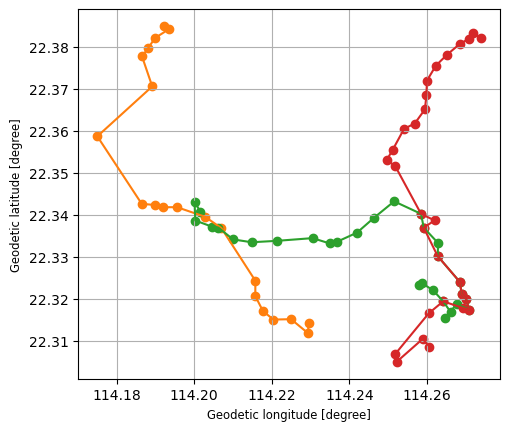

In [22]:
# take one of the route sequences (chose routeSeq = 1 and regular serviceMode)
line89_stops = bus_network.query("(routeNameC == '89') and (routeSeq == 1) and (serviceMode == 'R')")
line89_lines = gpd.GeoDataFrame(geometry=[LineString(line89_stops["geometry"])], crs=bus_network.crs)
line91M_stops = bus_network.query("(routeNameC == '91M') and (routeSeq == 1) and (serviceMode == 'R')")
line91M_lines = gpd.GeoDataFrame(geometry=[LineString(line91M_stops["geometry"])], crs=bus_network.crs)
line792M_stops = bus_network.query("(routeNameC == '792M') and (routeSeq == 1) and (serviceMode == 'R')")
line792M_lines = gpd.GeoDataFrame(geometry=[LineString(line792M_stops["geometry"])], crs=bus_network.crs)

ax = plt.axes()
line89_stops.plot(ax=ax, color='C1')
line89_lines.plot(ax=ax, color='C1')
line91M_stops.plot(ax=ax, color='C2')
line91M_lines.plot(ax=ax, color='C2')
line792M_stops.plot(ax=ax, color='C3')
line792M_lines.plot(ax=ax, color='C3')
ax.grid()

Above looks reasonable if you know your bus routes (89 goes from Lek Yuen to Kwun Tong, 91M from Diamond Hill to Po Lam, 792M from Sai Kung to TKO). Below I am going to plot this in cartopy, but I am additionally going to be fancy and plot this on a Google map that I am going to pull from the internet.

> NOTE: I cheated below a bit by being inconsistent with my map projection. The google map one is `Mercator` (query it with `request.crs`), but I am using `PlateCarree`. For small areas it probably doesn't matter, but if I don't do that my MTR and bus lines get transformed to somewhere else because of inconsistent projections. I could have tried to fix it, but I couldn't be bothered here...

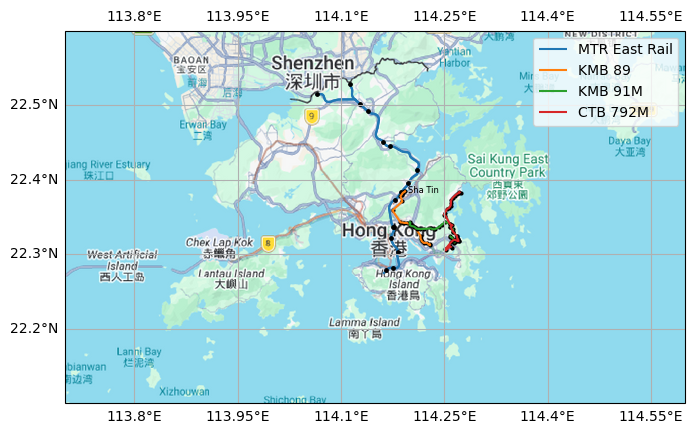

In [23]:
# cartopy it and do some even more fancy things
import cartopy.io.img_tiles as cimgt
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

def make_map(projection=ccrs.PlateCarree()):
    fig, ax = plt.subplots(figsize=(8, 6),
                           subplot_kw=dict(projection=projection))
    gl = ax.gridlines(draw_labels=True)
    gl.top_labels_top = gl.right_labels = False
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    return fig, ax

# request a google satellite image and plot on top of that
extent = [113.7, 114.6, 22.1, 22.6]
request = cimgt.GoogleTiles() # style="satellite" for satellite image; don't make extent too big

# be careful here: original has Mercator, but small area so maybe can get away with the mismatch
fig, ax = make_map(projection=ccrs.PlateCarree())
ax.set_extent(extent)
ax.add_image(request, 10, interpolation='spline36', zorder=-5)

EastRail_line.plot(ax=ax, label="MTR East Rail", zorder=1)
EastRail_stations.plot(ax=ax, color="k", markersize=6)
line89_stops.plot(ax=ax, color="k", markersize=4)
label = f"{line89_stops['companyCode'].unique()[0]} {line89_stops['routeNameC'].unique()[0]}"
line89_lines.plot(ax=ax, color='C1', label=label, zorder=1)
line91M_stops.plot(ax=ax, color="k", markersize=4)
label = f"{line91M_stops['companyCode'].unique()[0]} {line91M_stops['routeNameC'].unique()[0]}"
line91M_lines.plot(ax=ax, color='C2', label=label, zorder=1)
line792M_stops.plot(ax=ax, color="k", markersize=4)
label = f"{line792M_stops['companyCode'].unique()[0]} {line792M_stops['routeNameC'].unique()[0]}"
line792M_lines.plot(ax=ax, color='C3', label=label, zorder=1)

# add in the station names with an offset
for _, row in EastRail_stations.iterrows():
    if row["name_en"] == "Sha Tin":
        ax.annotate(
            text=row["name_en"],
            xy=(row["geometry"].x + 0.01, row["geometry"].y),  # cheating here
            ha='left',
            fontsize=6,
        )

ax.legend()

One thing I could do but I didn't is to create a bus network with the above data, where the bus stops are ***nodes***, the connections between bus stops are ***edges***, and the collection of that would be what is called a ***graph***. For a graph I may or may not care about the actual distances, but only how it is connected (e.g., a MTR map that you normally see on the MTR; it contains topological information but throws out some geometric information). If I include times, distances and/or fare princes between stops then I would have a ***weighted*** graph, and if directions matter then it would be a ***directed graph*** or ***digraph***. These are the objects that are analysed in ***network analysis***, asking questions such as:

* shortest distance between two stations
* cheapest route between two stations
* connectivity of the stations
* implied connectivity for areas

and others. You can imagine playing a similar game with things like roads, or water/sewage pipes, electric grid, and so forth, which are important for city and infrastructure design, e.g. planning for a new bus/MTR route, where to place new hospitals/police stations/fire stations/schools, so I suppose GIS is important because it powers those things.

You could imagine also how the above might work for studying disease spreading, ecological migration, ocean connectivity, evolution genetics, and others, so in that sense the GIS tools can powers those too if you like. I don't particularly want to sell that as GIS since if anything it's really the underlying manipulations of geometric/topological objects that in my opinion the engines of interest, and in that sense GIS is just the layer on top of that engine.

> <span style="color:red">**Q.**</span> See how you might construct networks accordingly. I would start with selecting a few lines where you know the lines do intersect (e.g. choose some lines that all stop at Choi Hung or Diamond Hill say).